In [1]:
from google.colab import files
uploaded = files.upload()

Saving WELFake_Dataset.csv to WELFake_Dataset.csv


In [2]:
import pandas as pd
df = pd.read_csv('WELFake_Dataset.csv')
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [3]:
print("Datset Shape:",df.shape)

print("\nColumn Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabele Distribution:")
print(df['label'].value_counts())

Datset Shape: (72134, 4)

Column Data Types:
Unnamed: 0     int64
title         object
text          object
label          int64
dtype: object

Missing Values:
Unnamed: 0      0
title         558
text           39
label           0
dtype: int64

Labele Distribution:
label
1    37106
0    35028
Name: count, dtype: int64


In [4]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Titles:", df['title'].duplicated().sum())

print("Duplicate Articles:", df['text'].duplicated().sum())

print("Unique Index Values:", df['Unnamed: 0'].nunique())

Duplicate Rows: 0
Duplicate Titles: 9786
Duplicate Articles: 9415
Unique Index Values: 72134


In [5]:
# Check how many unique labels exist for each identical article
text_label_counts = df.groupby('text')['label'].nunique()

# Count articles that have conflicting labels
conflicting_articles = (text_label_counts > 1).sum()

print("Articles with conflicting labels:", conflicting_articles)

# Count repeated article texts
print("Repeated article texts:", df['text'].duplicated().sum())

# Check repeated titles with conflicting labels
title_label_counts = df.groupby('title')['label'].nunique()

conflicting_titles = (title_label_counts > 1).sum()

print("Titles with conflicting labels:", conflicting_titles)

Articles with conflicting labels: 1
Repeated article texts: 9415
Titles with conflicting labels: 4


In [6]:
conflicting_texts = text_label_counts[text_label_counts > 1].index

df[df['text'].isin(conflicting_texts)][['title', 'text', 'label']]

,title,text,label
7,HOUSE INTEL CHAIR On Trump-Russia Fake Story: ...,,1
106,MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trum...,,1
325,Ohio State University Student Says Terrorist A...,,1
364,JULIAN ASSANGE REVEALS John Podesta’s Hilariou...,,1
512,OBAMA’S LIST OF 21 MEDAL OF FREEDOM Recipients...,,1
...,...,...,...
71771,WOW! JILL STEIN’S ‘FIRESIDE CHAT’ Exposes Her ...,,1
71914,WATCH TUCKER CARLSON Scorch Sanctuary City May...,,1
72026,BOOM! Woman Tries To Steal TRUMP Signs BUT Thi...,,1
72119,BILL O’REILLY Destroys Liberal Pundit On Trump...,,1


In [7]:
df[df['text'].notna() & df['title'].isna()][['title', 'text', 'label']]

,title,text,label
1,NaN,Did they post their votes for Hillary already?,1
43,NaN,True. Hillary needs a distraction and what bet...,1
162,NaN,All eyes on Electoral delegates. The People kn...,1
185,NaN,Cool,1
269,NaN,A leading US senator: US Supporting War in Syr...,1
...,...,...,...
71484,NaN,Another Arab supremacist masturbation fantasy....,1
71521,NaN,I'm sure they drastically changed accounting m...,1
71540,NaN,It's easy to imagine Obama or Kerry pissing hi...,1
71570,NaN,Ever since the powers to be assassinated JFK A...,1


In [8]:
df[df['text'].isin(conflicting_texts)][['title', 'text', 'label']].to_string(index=False)

'                                                                                                                                                                                                                           title text  label\n                                                                                                                                                 HOUSE INTEL CHAIR On Trump-Russia Fake Story: “No evidence of anything” [Video]           1\n                                                                                                                                                            MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trump Bias May Be Suicidal           1\n                                                                                                                             Ohio State University Student Says Terrorist Attack Was “Misunderstanding” Caused By Racism [VIDEO]           1\n                                               

In [9]:
for article in conflicting_texts:
    print("Article:", repr(article))
    print(df.loc[df['text'].eq(article), ['title', 'label']].to_string(index=False))

Article: ' '
                                                                                                                                                                                                                           title  label
                                                                                                                                                 HOUSE INTEL CHAIR On Trump-Russia Fake Story: “No evidence of anything” [Video]      1
                                                                                                                                                            MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trump Bias May Be Suicidal      1
                                                                                                                             Ohio State University Student Says Terrorist Attack Was “Misunderstanding” Caused By Racism [VIDEO]      1
                                                           

In [10]:
for article in conflicting_texts:
    rows = df[df['text'].eq(article)]
    print("Article length:", len(article))
    print("Number of records:", len(rows))
    print("Labels:", rows['label'].unique())
    print("Titles:")
    print(rows['title'].to_list())
    print("-" * 40)

Article length: 1
Number of records: 738
Labels: [1 0]
Titles:
['HOUSE INTEL CHAIR On Trump-Russia Fake Story: “No evidence of anything” [Video]', 'MARKETWATCH LEFTIST: MSM’s “Blatant” Anti Trump Bias May Be Suicidal', 'Ohio State University Student Says Terrorist Attack Was “Misunderstanding” Caused By Racism [VIDEO]', 'JULIAN ASSANGE REVEALS John Podesta’s Hilarious Email Password…”A 14 Year Old Kid Could’ve Hacked Podesta” [VIDEO]', 'OBAMA’S LIST OF 21 MEDAL OF FREEDOM Recipients Reads Like A Who’s Who Of The Far Left', 'HILARIOUS TRUMP CHRISTMAS VIDEO: “It’s The Most Wonderful Time In 8 Years” [Video]', 'AWESOME! JEWISH DEMOCRAT LEADER Hits Back At Harry Reid To Defend Trump Appointee: [Video]', 'WOW! LEGAL HISPANIC AMERICAN IMMIGRANT Unloads On Racist Hillary Supporters: “Liberals Are Desperate Because They Know They’re Gonna Lose” [VIDEO]', 'OBAMA DANCES At Last-Ever White House Gig To Drake’s “Hotline Bling” [Video]', 'TREY GOWDY ON SPYING ON AMERICAN CITIZENS…Like President Tru

In [11]:
df = df[df['text'].notna() & (df['text'].str.strip().str.len() > 1)].copy()

df['title'] = df['title'].fillna('')

df = df.drop(columns=['Unnamed: 0'])

print("Dataset shape after cleaning:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape after cleaning: (71349, 3)

Missing values:
title    0
text     0
label    0
dtype: int64


In [12]:
print("Label Counts:")
print(df['label'].value_counts())

print("\nLabel Percentages:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

Label Counts:
label
1    36322
0    35027
Name: count, dtype: int64

Label Percentages:
label
1    50.91
0    49.09
Name: proportion, dtype: float64


In [13]:
print("Duplicate Article Texts:", df['text'].duplicated().sum())

print(
    "Articles with Conflicting Labels:",
    df.groupby('text')['label'].nunique().gt(1).sum()
)

Duplicate Article Texts: 8636
Articles with Conflicting Labels: 0


In [14]:
df['content'] = df['title'] + ' ' + df['text']
print("Duplicate Complete Articales:",df['content'].duplicated().sum())

Duplicate Complete Articales: 8241


In [15]:
df = df.drop_duplicates(subset='content').copy()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicate Articles:", df['content'].duplicated().sum())

Dataset Shape After Removing Duplicates: (63108, 4)
Remaining Duplicate Articles: 0


In [16]:
print("Label Counts:")
print(df['label'].value_counts())

print("\nLabel Percentages:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

Label Counts:
label
0    34790
1    28318
Name: count, dtype: int64

Label Percentages:
label
0    55.13
1    44.87
Name: proportion, dtype: float64


In [17]:
x = df['content']
y = df['label']

print("Feature Shape:", x.shape)
print("Target Shape:", y.shape)

Feature Shape: (63108,)
Target Shape: (63108,)


In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (50486,)
Testing Data: (12622,)


In [19]:
print("Training Data Label Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Data Label Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Data Label Distribution:
label
0    0.551
1    0.449
Name: proportion, dtype: float64

Testing Data Label Distribution:
label
0    0.551
1    0.449
Name: proportion, dtype: float64


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(x_train)
X_test_tfidf = tfidf.transform(x_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (50486, 50000)
Testing TF-IDF Shape: (12622, 50000)


In [21]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [22]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = lr_model.predict(X_test_tfidf)

print("Accuracy:",accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Real News','Fake News']
))

Accuracy: 0.9493741086990968

Classification Report:
              precision    recall  f1-score   support

   Real News       0.95      0.96      0.95      6958
   Fake News       0.95      0.94      0.94      5664

    accuracy                           0.95     12622
   macro avg       0.95      0.95      0.95     12622
weighted avg       0.95      0.95      0.95     12622



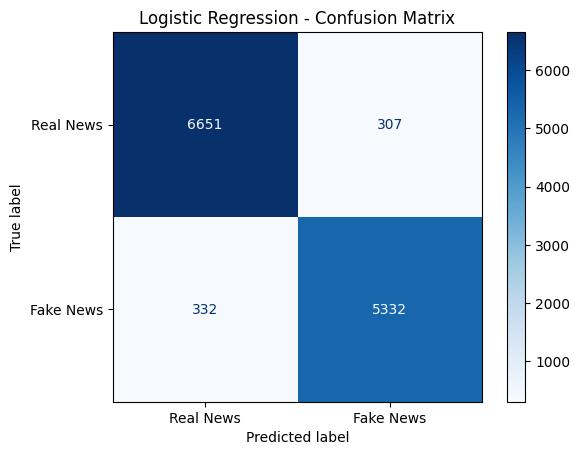

Confusion Matrix:
[[6651  307]
 [ 332 5332]]


In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Real News','Fake News']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

print("Confusion Matrix:")
print(cm)

In [24]:
y_train_pred = lr_model.predict(X_train_tfidf)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")
print("Difference:", round((train_accuracy - test_accuracy) * 100, 2), "%")

Training Accuracy: 96.72 %
Testing Accuracy: 94.94 %
Difference: 1.79 %


In [25]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [26]:
from sklearn.metrics import accuracy_score, classification_report

nb_pred = nb_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, nb_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_pred,
    target_names=['Real News', 'Fake News']
))

Accuracy: 0.8766439549992078

Classification Report:
              precision    recall  f1-score   support

   Real News       0.90      0.87      0.89      6958
   Fake News       0.85      0.88      0.87      5664

    accuracy                           0.88     12622
   macro avg       0.87      0.88      0.88     12622
weighted avg       0.88      0.88      0.88     12622



In [27]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

LinearSVC()

In [28]:
from sklearn.metrics import accuracy_score, classification_report

svm_pred = svm_model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    target_names=['Real News', 'Fake News']
))

Accuracy: 0.9605450800190144

Classification Report:
              precision    recall  f1-score   support

   Real News       0.96      0.97      0.96      6958
   Fake News       0.96      0.95      0.96      5664

    accuracy                           0.96     12622
   macro avg       0.96      0.96      0.96     12622
weighted avg       0.96      0.96      0.96     12622



In [29]:
svm_train_pred = svm_model.predict(X_train_tfidf)

svm_train_accuracy = accuracy_score(y_train, svm_train_pred)
svm_test_accuracy = accuracy_score(y_test, svm_pred)

print("Training Accuracy:", round(svm_train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(svm_test_accuracy * 100, 2), "%")
print("Difference:", round((svm_train_accuracy - svm_test_accuracy) * 100, 2), "%")

Training Accuracy: 99.72 %
Testing Accuracy: 96.05 %
Difference: 3.67 %


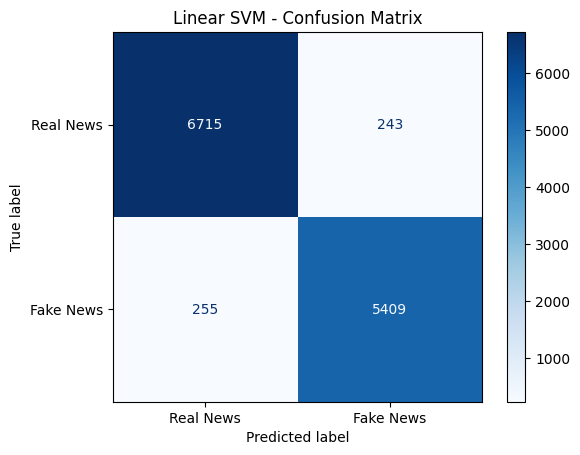

Confusion Matrix:
[[6715  243]
 [ 255 5409]]


In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

svm_cm = confusion_matrix(y_test, svm_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=['Real News', 'Fake News']
)

disp.plot(cmap='Blues')
plt.title('Linear SVM - Confusion Matrix')
plt.show()

print("Confusion Matrix:")
print(svm_cm)

In [31]:
train_texts = set(df.loc[x_train.index, 'text'])
test_texts = set(df.loc[x_test.index, 'text'])

overlap = train_texts.intersection(test_texts)

print("Article bodies appearing in both sets:", len(overlap))

Article bodies appearing in both sets: 51


In [32]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

train_idx, test_idx = next(gss.split(x, y, groups=df['text']))

x_train, x_test = x.iloc[train_idx], x.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

print("\nTraining Label Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Label Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Data: (50493,)
Testing Data: (12615,)

Training Label Distribution:
label
0    0.551
1    0.449
Name: proportion, dtype: float64

Testing Label Distribution:
label
0    0.554
1    0.446
Name: proportion, dtype: float64


In [33]:
train_texts = set(df.iloc[train_idx]['text'])
test_texts = set(df.iloc[test_idx]['text'])

overlap = train_texts.intersection(test_texts)

print("Article bodies appearing in both sets:", len(overlap))

Article bodies appearing in both sets: 0


In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(x_train)
X_test_tfidf = tfidf.transform(x_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (50493, 50000)
Testing TF-IDF Shape: (12615, 50000)


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Linear SVM
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)

print("All 3 models retrained successfully!")

All 3 models retrained successfully!


In [36]:
from sklearn.metrics import accuracy_score, classification_report

# Predictions
lr_pred = lr_model.predict(X_test_tfidf)
nb_pred = nb_model.predict(X_test_tfidf)
svm_pred = svm_model.predict(X_test_tfidf)

# Logistic Regression
print("===== Logistic Regression =====")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred, target_names=['Real News', 'Fake News']))

# Naive Bayes
print("\n===== Multinomial Naive Bayes =====")
print("Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(y_test, nb_pred, target_names=['Real News', 'Fake News']))

# Linear SVM
print("\n===== Linear SVM =====")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred, target_names=['Real News', 'Fake News']))

===== Logistic Regression =====
Accuracy: 0.9483154974237019
              precision    recall  f1-score   support

   Real News       0.95      0.95      0.95      6985
   Fake News       0.94      0.94      0.94      5630

    accuracy                           0.95     12615
   macro avg       0.95      0.95      0.95     12615
weighted avg       0.95      0.95      0.95     12615


===== Multinomial Naive Bayes =====
Accuracy: 0.8779231074118113
              precision    recall  f1-score   support

   Real News       0.90      0.88      0.89      6985
   Fake News       0.85      0.88      0.87      5630

    accuracy                           0.88     12615
   macro avg       0.88      0.88      0.88     12615
weighted avg       0.88      0.88      0.88     12615


===== Linear SVM =====
Accuracy: 0.9606817281014665
              precision    recall  f1-score   support

   Real News       0.96      0.97      0.96      6985
   Fake News       0.96      0.95      0.96      5630

  

In [37]:
from sklearn.metrics import accuracy_score

# Training predictions
lr_train_pred = lr_model.predict(X_train_tfidf)
nb_train_pred = nb_model.predict(X_train_tfidf)
svm_train_pred = svm_model.predict(X_train_tfidf)

# Training accuracy
lr_train_acc = accuracy_score(y_train, lr_train_pred)
nb_train_acc = accuracy_score(y_train, nb_train_pred)
svm_train_acc = accuracy_score(y_train, svm_train_pred)

# Testing accuracy
lr_test_acc = accuracy_score(y_test, lr_pred)
nb_test_acc = accuracy_score(y_test, nb_pred)
svm_test_acc = accuracy_score(y_test, svm_pred)

# Results
print("Logistic Regression")
print(f"Training Accuracy: {lr_train_acc * 100:.2f}%")
print(f"Testing Accuracy: {lr_test_acc * 100:.2f}%")
print(f"Difference: {(lr_train_acc - lr_test_acc) * 100:.2f}%")

print("\nMultinomial Naive Bayes")
print(f"Training Accuracy: {nb_train_acc * 100:.2f}%")
print(f"Testing Accuracy: {nb_test_acc * 100:.2f}%")
print(f"Difference: {(nb_train_acc - nb_test_acc) * 100:.2f}%")

print("\nLinear SVM")
print(f"Training Accuracy: {svm_train_acc * 100:.2f}%")
print(f"Testing Accuracy: {svm_test_acc * 100:.2f}%")
print(f"Difference: {(svm_train_acc - svm_test_acc) * 100:.2f}%")

Logistic Regression
Training Accuracy: 96.73%
Testing Accuracy: 94.83%
Difference: 1.90%

Multinomial Naive Bayes
Training Accuracy: 89.31%
Testing Accuracy: 87.79%
Difference: 1.52%

Linear SVM
Training Accuracy: 99.74%
Testing Accuracy: 96.07%
Difference: 3.67%


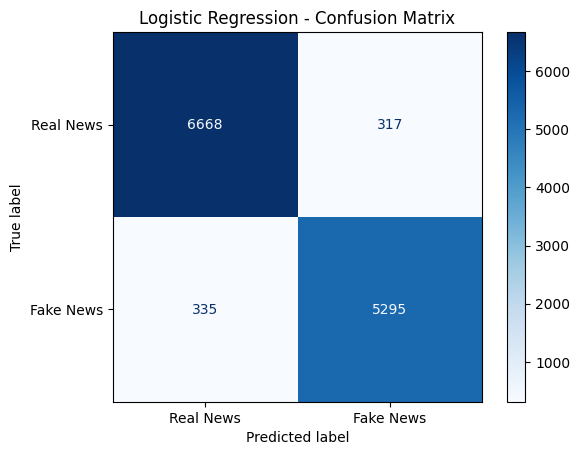

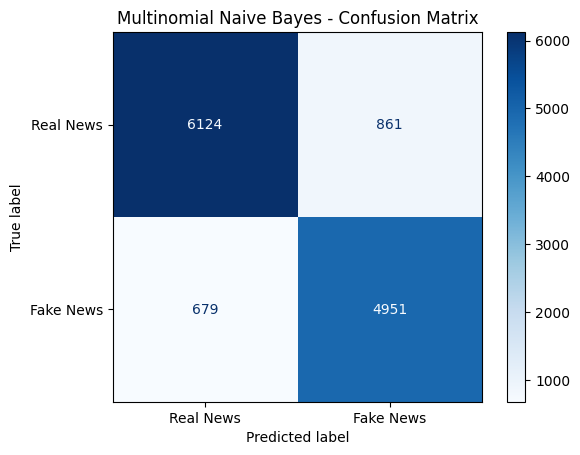

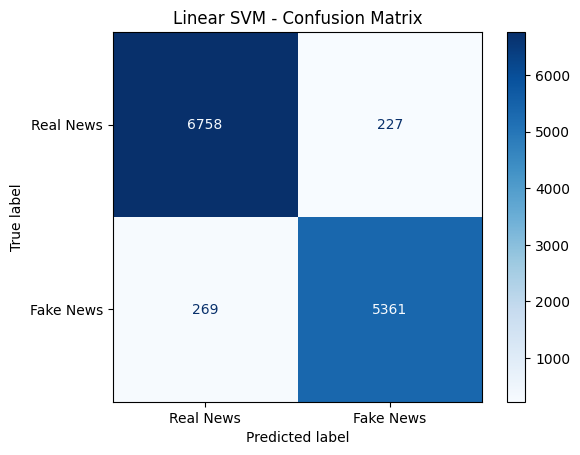

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion matrices
lr_cm = confusion_matrix(y_test, lr_pred)
nb_cm = confusion_matrix(y_test, nb_pred)
svm_cm = confusion_matrix(y_test, svm_pred)

# Logistic Regression
ConfusionMatrixDisplay(lr_cm, display_labels=['Real News', 'Fake News']).plot(cmap='Blues')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Naive Bayes
ConfusionMatrixDisplay(nb_cm, display_labels=['Real News', 'Fake News']).plot(cmap='Blues')
plt.title("Multinomial Naive Bayes - Confusion Matrix")
plt.show()

# Linear SVM
ConfusionMatrixDisplay(svm_cm, display_labels=['Real News', 'Fake News']).plot(cmap='Blues')
plt.title("Linear SVM - Confusion Matrix")
plt.show()

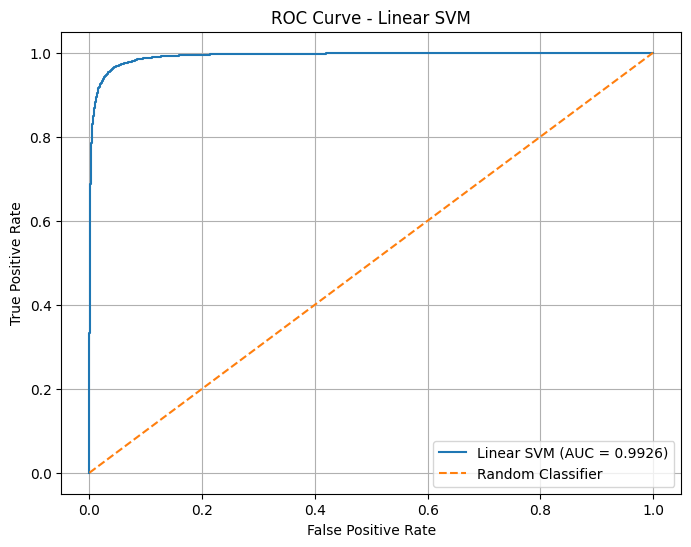

ROC-AUC Score: 0.9925888639828305


In [39]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get decision scores from Linear SVM
svm_scores = svm_model.decision_function(X_test_tfidf)

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, svm_scores)

# Calculate AUC
auc_score = roc_auc_score(y_test, svm_scores)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Linear SVM (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Linear SVM')
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", auc_score)

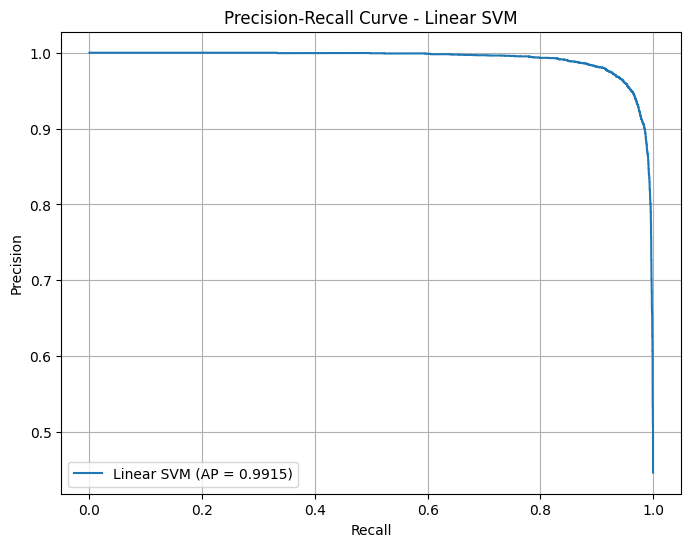

Average Precision Score: 0.991544398429725


In [40]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(y_test, svm_scores)

# Calculate Average Precision
ap_score = average_precision_score(y_test, svm_scores)

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Linear SVM (AP = {ap_score:.4f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Linear SVM')
plt.legend()
plt.grid()
plt.show()

print("Average Precision Score:", ap_score)

In [41]:
# Create a results DataFrame
results = pd.DataFrame({
    'Article': x_test.values,
    'Actual': y_test.values,
    'Predicted': svm_pred
})

# Select incorrectly classified articles
errors = results[results['Actual'] != results['Predicted']]

print("Total Misclassified Articles:", len(errors))

# Display first 5 errors
for index, row in errors.head(5).iterrows():
    print("\n" + "=" * 70)
    print("Actual:", "Fake News" if row['Actual'] == 1 else "Real News")
    print("Predicted:", "Fake News" if row['Predicted'] == 1 else "Real News")
    print("Article:", row['Article'][:500])

Total Misclassified Articles: 496

Actual: Fake News
Predicted: Real News
Article: About Time! Christian Group Sues Amazon and SPLC for Designation as Hate Group All we can say on this one is it s about time someone sued the Southern Poverty Law Center!On Tuesday, D. James Kennedy Ministries (DJKM) filed a lawsuit against the Southern Poverty Law Center (SPLC), the charity navigation organization GuideStar, and Amazon, for defamation, religious discrimination, and trafficking in falsehood. The SPLC listed DJKM as a  hate group,  while GuideStar also categorized it in those ter

Actual: Fake News
Predicted: Real News
Article: Homeschooling and Other Education Alternatives on the Rise Email 
Horace Mann, the first secretary of the Massachusetts Board of Education, speaking a few years before the Civil War, declared that public schools constituted “the greatest discovery ever made by man." He added, "Let the common [public) school be expanded to its capabilities, let it be worked with the

In [42]:
# Get prediction scores
error_analysis = pd.DataFrame({
    'Article': x_test.values,
    'Actual': y_test.values,
    'Predicted': svm_pred,
    'Decision Score': svm_scores
})

# Select misclassified articles
errors = error_analysis[
    error_analysis['Actual'] != error_analysis['Predicted']
].copy()

# Calculate distance from decision boundary
errors['Confidence Distance'] = errors['Decision Score'].abs()

# Show 10 errors closest to the decision boundary
uncertain_errors = errors.sort_values(
    by='Confidence Distance'
).head(10)

print("10 Most Uncertain Misclassified Articles:")

for _, row in uncertain_errors.iterrows():
    print("\n" + "=" * 60)
    print("Actual:", "Fake" if row['Actual'] == 1 else "Real")
    print("Predicted:", "Fake" if row['Predicted'] == 1 else "Real")
    print("Decision Score:", round(row['Decision Score'], 4))
    print("Article:", row['Article'][:300])

10 Most Uncertain Misclassified Articles:

Actual: Real
Predicted: Fake
Decision Score: 0.0001
Article: John McCain Withdraws Support of Donald Trump John McCain is done with Trump. Countless Republicans have tried to distance themselves from Donald Trump in the 24 hours since The Washington Post released an audio recording wherein the Republican standard-bearer made a series of lewd comments about wo

Actual: Fake
Predicted: Real
Decision Score: -0.0034
Article: WOW! RUSSIAN HACKER Gives Stunning Details Of Deal FBI Offered Him To Falsely Claim He Hacked Hillary’s Email On Behalf Of Putin For Trump A Russian man wanted by the Justice Department on charges connected to hacking U.S. companies now claims the FBIoffered him immunity in exchange for accepting re

Actual: Fake
Predicted: Real
Decision Score: -0.0058
Article: DEMOCRATS THREATEN KIDS EDUCATION: CHICAGO TEACHERS UNION DEMANDS RAISES AS Chicago Public Schools Run Out Of Money In One Week It s painful to watch the stupidity and 

In [43]:
import joblib

# Save the trained vectorizer
joblib.dump(tfidf, 'verinews_tfidf.pkl')

# Save the trained Linear SVM model
joblib.dump(svm_model, 'verinews_svm_model.pkl')

print("Vectorizer and Linear SVM model saved successfully!")

Vectorizer and Linear SVM model saved successfully!


In [44]:
import zipfile

with zipfile.ZipFile('VeriNews_AI_Models.zip', 'w') as zipf:
    zipf.write('verinews_tfidf.pkl')
    zipf.write('verinews_svm_model.pkl')

from google.colab import files
files.download('VeriNews_AI_Models.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
loaded_tfidf = joblib.load('verinews_tfidf.pkl')
loaded_model = joblib.load('verinews_svm_model.pkl')

print("TF-IDF Vectorizer Loaded:", loaded_tfidf is not None)
print("SVM Model Loaded:", loaded_model is not None)

TF-IDF Vectorizer Loaded: True
SVM Model Loaded: True


In [46]:
sample_article = """
Scientists have announced a new breakthrough in renewable energy
technology that could significantly improve solar panel efficiency.
"""

# Convert text into TF-IDF features
sample_tfidf = loaded_tfidf.transform([sample_article])

# Predict using the loaded SVM model
prediction = loaded_model.predict(sample_tfidf)

if prediction[0] == 1:
    print("Prediction: Fake News")
else:
    print("Prediction: Real News")

Prediction: Fake News


In [47]:
decision_score = loaded_model.decision_function(sample_tfidf)

print("Decision Score:", decision_score[0])


Decision Score: 0.3672423746746137


In [48]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 46.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 94.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [49]:
%%writefile app.py

import streamlit as st
import joblib

# Load trained model and TF-IDF vectorizer
@st.cache_resource
def load_models():
    tfidf = joblib.load('verinews_tfidf.pkl')
    model = joblib.load('verinews_svm_model.pkl')
    return tfidf, model

tfidf, model = load_models()

# Page configuration
st.set_page_config(
    page_title="VeriNews AI",
    page_icon="📰",
    layout="centered"
)

# Application heading
st.title("📰 VeriNews AI")
st.subheader("Intelligent News Classification System")

st.write(
    "Enter a news article below to classify it using "
    "our trained Machine Learning model."
)

# Article input
article = st.text_area(
    "Paste your news article here:",
    height=250,
    placeholder="Enter the news article..."
)

# Prediction
if st.button("Classify News"):
    if article.strip():
        article_tfidf = tfidf.transform([article])

        prediction = model.predict(article_tfidf)[0]
        score = model.decision_function(article_tfidf)[0]

        st.subheader("Classification Result")

        if prediction == 1:
            st.error("Prediction: Fake News")
        else:
            st.success("Prediction: Real News")

        st.write(f"Decision Score: {score:.4f}")

        if score > 0:
            st.write("The model classified the article as Fake.")
        else:
            st.write("The model classified the article as Real.")

    else:
        st.warning("Please enter a news article first.")

# Disclaimer
st.divider()
st.caption(
    "Disclaimer: This application identifies patterns learned "
    "from the WELFake dataset. It does not independently verify "
    "the factual accuracy of news articles."
)

Writing app.py


In [50]:
from google.colab import files

uploaded = files.upload()

Saving VeriNews_AI_Models.zip to VeriNews_AI_Models (1).zip


In [51]:
import zipfile

with zipfile.ZipFile('VeriNews_AI_Models (1).zip', 'r') as zipf:
    zipf.extractall()

print("Model files extracted successfully!")

Model files extracted successfully!


In [52]:
import os

required_files = [
    'app.py',
    'verinews_tfidf.pkl',
    'verinews_svm_model.pkl'
]

for file in required_files:
    if os.path.exists(file):
        print(f"Found: {file}")
    else:
        print(f"Missing: {file}")

Found: app.py
Found: verinews_tfidf.pkl
Found: verinews_svm_model.pkl


In [53]:
!streamlit run app.py --server.port 8502 --server.headless true > streamlit.log 2>&1 &

In [54]:
!cat streamlit.log

In [55]:
!cat streamlit.log

In [56]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8502)"))

https://8502-m-s-euw4b0-j6h5tw1mxsjc-b.europe-west4.prod.r.colab.dev


In [57]:
!curl -I http://localhost:8502

HTTP/1.1 200 OK
date: Sat, 21 Nov 2026 09:08:02 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Sat, 21 Nov 2026 09:05:49 GMT
etag: "bbde5f8531831c2c577c86b10ee9bf3d"
cache-control: no-cache



In [58]:
!tail -n 30 streamlit.log



2026-11-21 09:08:02.929 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.32.208.48:8502



In [59]:
!pkill -f "streamlit run app.py" || true


^C


In [60]:
!pgrep -af streamlit

9948 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8502 --server.headless true


In [61]:
!streamlit run app.py \
    --server.port 8502 \
    --server.address 0.0.0.0 \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    --server.headless true \
    > streamlit.log 2>&1 &

In [62]:
!tail -n 10 streamlit.log

In [63]:

%%writefile app.py

import streamlit as st
import joblib

# ----------------------------------
# Load Trained Model and Vectorizer
# ----------------------------------

@st.cache_resource
def load_models():
    tfidf = joblib.load('verinews_tfidf.pkl')
    model = joblib.load('verinews_svm_model.pkl')
    return tfidf, model


tfidf, model = load_models()


# ----------------------------------
# Page Configuration
# ----------------------------------

st.set_page_config(
    page_title="VeriNews AI",
    page_icon="📰",
    layout="centered"
)


# ----------------------------------
# Application Heading
# ----------------------------------

st.title("📰 VeriNews AI")

st.subheader("Intelligent News Classification System")

st.write(
    "Analyze news articles using a Machine Learning "
    "model trained on the WELFake dataset."
)


# ----------------------------------
# User Input
# ----------------------------------

title = st.text_input(
    "News Headline",
    placeholder="Enter the news headline..."
)

article = st.text_area(
    "News Article",
    height=250,
    placeholder="Paste the complete news article here..."
)


# ----------------------------------
# News Classification
# ----------------------------------

if st.button("Classify News", type="primary"):

    if title.strip() and article.strip():

        # Combine headline and article
        content = title.strip() + " " + article.strip()

        # Convert text into TF-IDF features
        article_tfidf = tfidf.transform([content])

        # Make prediction
        prediction = model.predict(article_tfidf)[0]

        # Calculate SVM decision score
        score = model.decision_function(article_tfidf)[0]


        # ----------------------------------
        # Classification Result
        # ----------------------------------

        st.divider()

        st.header("Classification Result")

        if prediction == 1:

            st.error("🚨 Prediction: Fake News")

            category = "Fake News"

            explanation = (
                "The model's decision score is positive, "
                "so it classified the input as Fake News."
            )

        else:

            st.success("✅ Prediction: Real News")

            category = "Real News"

            explanation = (
                "The model's decision score is negative, "
                "so it classified the input as Real News."
            )


        # Display prediction details
        st.metric(
            label="Predicted Category",
            value=category
        )

        st.metric(
            label="SVM Decision Score",
            value=f"{score:.4f}"
        )


        # ----------------------------------
        # Prediction Explanation
        # ----------------------------------

        st.subheader("Why This Prediction?")

        st.write(explanation)

        st.info(
            "A positive decision score indicates Fake News, "
            "while a negative score indicates Real News. "
            "The absolute score measures distance from the "
            "decision boundary, not a probability."
        )


        # ----------------------------------
        # Influential Word Analysis
        # ----------------------------------

        st.subheader("Important Influential Words")

        feature_names = tfidf.get_feature_names_out()

        # Calculate each feature's contribution
        contributions = (
            article_tfidf.multiply(model.coef_[0])
            .toarray()
            .flatten()
        )

        # Select the top five contributing features
        if prediction == 1:

            top_indices = contributions.argsort()[-5:][::-1]

            st.write(
                "Words and phrases contributing most "
                "toward the Fake classification:"
            )

        else:

            top_indices = contributions.argsort()[:5]

            st.write(
                "Words and phrases contributing most "
                "toward the Real classification:"
            )


        # Display influential words
        displayed_words = 0

        for index in top_indices:

            contribution = contributions[index]

            if contribution != 0:

                st.write(
                    f"- **{feature_names[index]}** "
                    f"({contribution:.4f})"
                )

                displayed_words += 1


        if displayed_words == 0:

            st.write(
                "No individual word contributions "
                "were available for display."
            )


        # ----------------------------------
        # Disclaimer
        # ----------------------------------

        st.warning(
            "This prediction is based on patterns learned "
            "from the WELFake dataset. The influential words "
            "show model contributions, not evidence of "
            "factual accuracy. This application does not "
            "independently verify news articles."
        )


    else:

        st.warning(
            "Please enter both the headline and news article."
        )


# ----------------------------------
# Footer
# ----------------------------------

st.divider()

st.caption(
    "VeriNews AI | Machine Learning News Classification"
)


Overwriting app.py
